# SEM basics · 2 — choosing an equation

`sweep.sem` has sixteen equation classes. They all run through the same
`PropSEM(Equation, shape=..., ...)` and the same call, so the choice is about the
physics and about which backend can run it. This notebook:

1. **Reads the equation table** — what the names mean and what each column says
2. **Asks each equation what it needs** — `models=`, default source and receiver, backend
3. **Runs four 2-D equations on one model** — two acoustic, two elastic — and compares the records

About a minute on a GPU, most of it compiling the eager steps on first use.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

import sweep.sem as sem
from sweep.sem import PropSEM, suggest_discretization
from sweep.sem.equations import (describe, AcousticPotentialSEM2D,
                                 AcousticSEM2DDeformed, ElasticSEM2DDeformed,
                                 ElasticVSSEM2DDeformed)
from sweep.signal import ricker

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


## 1. The equation table

`describe()` prints one line per equation (`sweep list equations` and
`sweep show <Equation>` print the same from the command line):

In [2]:
print(describe())

  equation                   mesh   D  topo  cpml  flds  records
  --------------------------------------------------------------
  AcousticElasticSEM2D       quad9  2   yes split    16  chi, u_x, u_z
  AcousticPotentialSEM2D     quad9  2   yes   yes     6  chi
  AcousticSEM2D              quad4  2    no   yes     6  u
  AcousticSEM2DDeformed      quad9  2   yes   yes     6  u
  AcousticSEM3D              hex8   3    no   yes     8  u
  AcousticSEM3DDeformed      hex27  3   yes   yes     8  u
  BiotAnisoPermSEM2DDeformed quad9  2   yes   yes    22  v_x, v_z, p, q_x, q_z, sigma_xx, sigma_zz, sigma_xz
  BiotVSSEM2DDeformed        quad9  2   yes   yes    22  v_x, v_z, p, q_x, q_z, sigma_xx, sigma_zz, sigma_xz
  ElasticSEM2D               quad4  2    no    NO     4  u_x, u_z
  ElasticSEM2DDeformed       quad9  2   yes   yes    10  u_x, u_z
  ElasticSEM3D               hex8   3    no    NO     6  u_x, u_y, u_z
  ElasticSEM3DDeformed       hex27  3   yes    NO     6  u_x, u_y, u_z
  ElasticV

How to read it:

- **the name** — `Acoustic`, `Elastic`, `Biot` (poroelastic) or `AcousticElastic`
  (fluid–solid coupled); `VS` = first-order velocity–stress, otherwise
  second-order in displacement (or pressure); `VTI` = transversely isotropic;
  `Potential` = SPECFEM's fluid potential form; `3D` or `2D`.
- **mesh** — `quad4` / `hex8` are flat, axis-aligned meshes; `quad9` / `hex27`
  are deformable and accept `topography` (the **topo** column).
- **cpml** — whether the equation carries `PropSEM`'s C-PML absorbing layer.
  The three with `NO` (`ElasticSEM2D`, `ElasticSEM3D`, `ElasticSEM3DDeformed`) only
  run as a closed, reflecting box (`abcn=0`); use their `Deformed` or `VS`
  siblings for open models. `split` = an acoustic and an elastic profile, built
  for you.
- **flds / records** — the number of state fields, and the ones a receiver can
  record directly. Derived receivers (`p`, `vx`, `vz`) come on top; see the next
  notebook.

## 2. What each equation needs

A constructed solver reports what it takes: `model_names` is the `models=` list in
order, `impl` the backend it resolved to (`'c'` = the CUDA kernels, `'eager'` =
PyTorch), and `source_type` / `receiver_type` the defaults. Building a solver is
cheap, so we build each on a small grid:

In [3]:
rows = []
for name, cls in sorted(sem.equations.equation_classes().items()):
    ndim = sem.equations.summary(cls)['ndim']
    shape = (17,) * ndim
    try:
        s = PropSEM(cls, shape=shape, dh=10.0, dt=1e-3, abcn=8, device=device)
        rows.append((name, ', '.join(s.model_names), s.impl,
                     ','.join(s.source_type), ','.join(s.receiver_type)))
    except NotImplementedError:
        rows.append((name, '(no C-PML: abcn=0 only)', '', '', ''))

print(f"{'equation':28s} {'models=':42s} {'impl':6s} {'source':12s} receivers")
for r in rows:
    print(f'{r[0]:28s} {r[1]:42s} {r[2]:6s} {r[3]:12s} {r[4]}')

equation                     models=                                    impl   source       receivers
AcousticElasticSEM2D         vp, vs, rho                                c      chi          chi,u_x,u_z
AcousticPotentialSEM2D       vp                                         c      chi          chi
AcousticSEM2D                vp                                         eager  u            u
AcousticSEM2DDeformed        vp                                         eager  u            u
AcousticSEM3D                vp                                         c      u            u
AcousticSEM3DDeformed        vp                                         c      u            u
BiotAnisoPermSEM2DDeformed   H, mu, C, M, rho, rho_f, m, b_xx, b_xz, b_zz eager  sxx,szz      v_x,v_z
BiotVSSEM2DDeformed          H, mu, C, M, rho, rho_f, m, b              eager  sxx,szz      v_x,v_z
ElasticSEM2D                 (no C-PML: abcn=0 only)                                        
ElasticSEM2DDeformed       

Things worth knowing from this table:

- **`impl='c'`** (fused CUDA kernels, on a GPU) exists for `AcousticPotentialSEM2D`,
  `ElasticSEM2DDeformed`, the fluid–solid `AcousticElasticSEM2D`, and the 3-D
  `AcousticSEM3D`, `AcousticSEM3DDeformed` and `ElasticVSSEM3D`. Everything else
  runs eager (compiled PyTorch), on the GPU or the CPU. `impl='eager'` forces
  eager for any equation.
- **Acoustic models** are `[vp]` with a constant density (`density=` on
  `PropSEM`, default 1000). **Elastic** ones are `[vp, vs, rho]`, the VTI one adds
  Thomsen's `epsilon, delta`. **Biot** takes its eight poroelastic coefficients
  (build them with `sweep.equations.biot.biot_from_rock`).
- Every model is a grid tensor with the shape of `shape`, like on `PropTorch`.

A practical shortlist for 2-D:

| you want | use | backend |
| --- | --- | --- |
| acoustic modelling / FWI, fast, many shots | `AcousticPotentialSEM2D` | `'c'` |
| acoustic, simplest pressure form | `AcousticSEM2DDeformed` (`AcousticSEM2D` if flat) | eager |
| elastic modelling / FWI, fast | `ElasticSEM2DDeformed` | `'c'` |
| elastic with stress sources / velocity–stress | `ElasticVSSEM2DDeformed` | eager |
| VTI elastic | `ElasticVTISEM2DDeformed` | eager |
| water over an elastic sea floor | `AcousticElasticSEM2D` | `'c'` |
| poroelastic | `BiotVSSEM2DDeformed` | eager |

## 3. Four equations on one model

A two-layer model with a free surface on top: a source 200 m deep and a line
of receivers 20 m deep. The acoustic equations see `vp` only; the elastic ones see
`vp, vs, rho`.

In [4]:
dh, n_order = 10.0, 4
shape = (97, 193)                          # 960 m x 1920 m, 24 x 48 elements
f0 = 8.0
d = suggest_discretization((shape[1] - 1) * dh, (shape[0] - 1) * dh,
                           v_min=1000.0, v_max=2500.0, f0=f0, n_order=n_order)
print(d)
dt = 0.8e-3                                # just below the suggested step
nt = 1500

vp  = torch.full(shape, 1800.0); vp[48:]  = 2500.0
vs  = torch.full(shape, 1000.0); vs[48:]  = 1400.0
rho = torch.full(shape, 2000.0); rho[48:] = 2200.0
vp, vs, rho = (m.to(device) for m in (vp, vs, rho))

wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
src = np.array([[shape[1] // 2, 20]])                      # [ix, iz]
rx = np.arange(4, shape[1] - 4, 2)
rec = np.stack([rx, np.full_like(rx, 2)], axis=1)[None]   # (1, nrec, 2)
print('sources', src.shape, ' receivers', rec.shape)

SEMDiscretization(n_order=4, nex=48, nez=24, dt=8.20e-04  |  λ_min=50.0 m, h_e≈40×40 m, 5.0 pts/λ)
sources (1, 2)  receivers (1, 93, 2)


The acoustic equations record their own field (`chi` on the potential form, `u`
on the pressure form), the elastic ones the vertical particle velocity (`['vz']`)
of a vertical point force (`['vz']`), the same names on both. Everything else is
the same call:

In [5]:
runs = {
    'AcousticPotentialSEM2D': (AcousticPotentialSEM2D, [vp],          ['chi']),
    'AcousticSEM2DDeformed':  (AcousticSEM2DDeformed,  [vp],          ['u']),
    'ElasticSEM2DDeformed':   (ElasticSEM2DDeformed,   [vp, vs, rho], ['vz']),
    'ElasticVSSEM2DDeformed': (ElasticVSSEM2DDeformed, [vp, vs, rho], ['vz']),
}
records = {}
for name, (eq, models, rtype) in runs.items():
    kw = {} if eq in (AcousticPotentialSEM2D, AcousticSEM2DDeformed) else \
         dict(source_type=['vz'])
    solver = PropSEM(eq, shape=shape, dh=dh, dt=dt, n_order=n_order, abcn=40,
                     free_surface=True, f_dominant=f0, receiver_type=rtype,
                     device=device, **kw)
    for rep in range(2):                   # the 2nd call shows the time without compiling
        t0 = time.perf_counter()
        with torch.no_grad():
            out = solver(wavelet, src, rec, models=models)
        if device == 'cuda':
            torch.cuda.synchronize()
        sec = time.perf_counter() - t0
    records[name] = out[0, :, :, 0].cpu().numpy()
    print(f'{name:24s} impl={solver.impl:5s} record {tuple(out.shape)}  {sec:.2f} s')

AcousticPotentialSEM2D   impl=c     record (1, 1500, 93, 1)  0.03 s


sweep: torch.compile is compiling the AcousticSEM2DDeformed step for a 97x193 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


AcousticSEM2DDeformed    impl=eager record (1, 1500, 93, 1)  0.07 s


ElasticSEM2DDeformed     impl=c     record (1, 1500, 93, 1)  0.04 s


sweep: torch.compile is compiling the ElasticVSSEM2DDeformed step for a 97x193 grid


ElasticVSSEM2DDeformed   impl=eager record (1, 1500, 93, 1)  0.08 s


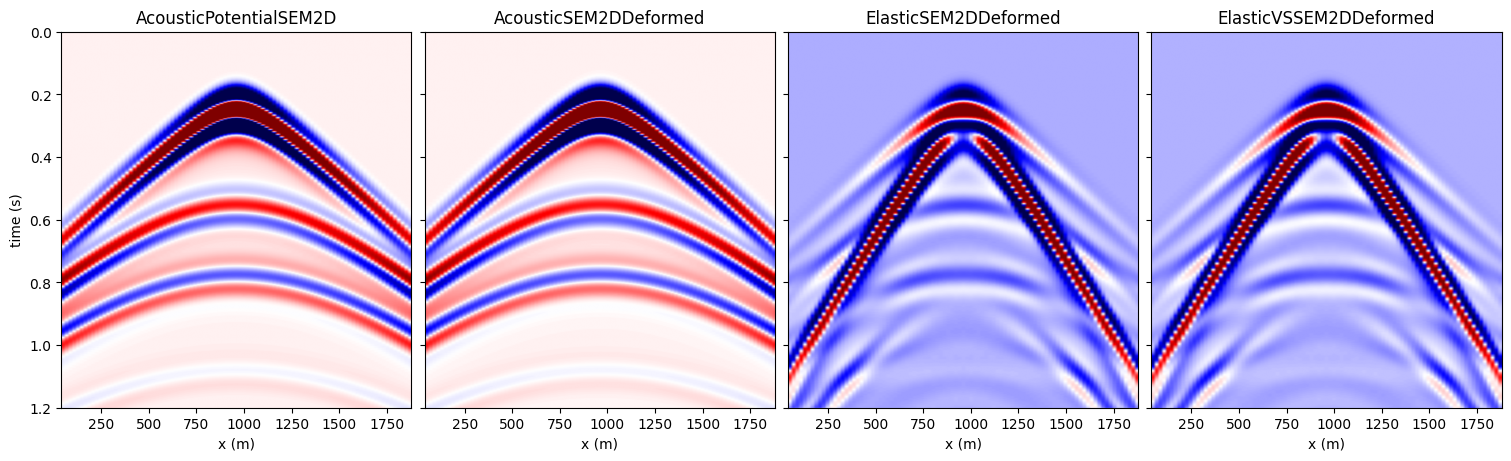

In [6]:
def show(ax, g, title):
    v = g[g != 0]
    lo, hi = np.percentile(v, [2, 98])
    ax.imshow(g, cmap='seismic', vmin=lo, vmax=hi, aspect='auto',
              extent=[rx[0] * dh, rx[-1] * dh, nt * dt, 0])
    ax.set_title(title); ax.set_xlabel('x (m)')

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), sharey=True, constrained_layout=True)
for ax, (name, g) in zip(axes, records.items()):
    show(ax, g, name)
axes[0].set_ylabel('time (s)')
plt.show()

The two acoustic records show the direct wave, the reflection from the layer
boundary at 480 m and the free-surface ghosts and multiples. The two elastic
ones add converted and shear waves and the Rayleigh wave along the surface.
Within each pair the formulation differs but the physics is the same, so the
traces agree in shape. Their amplitude scales are not the same (each equation
has its own source normalization), so compare them normalized:

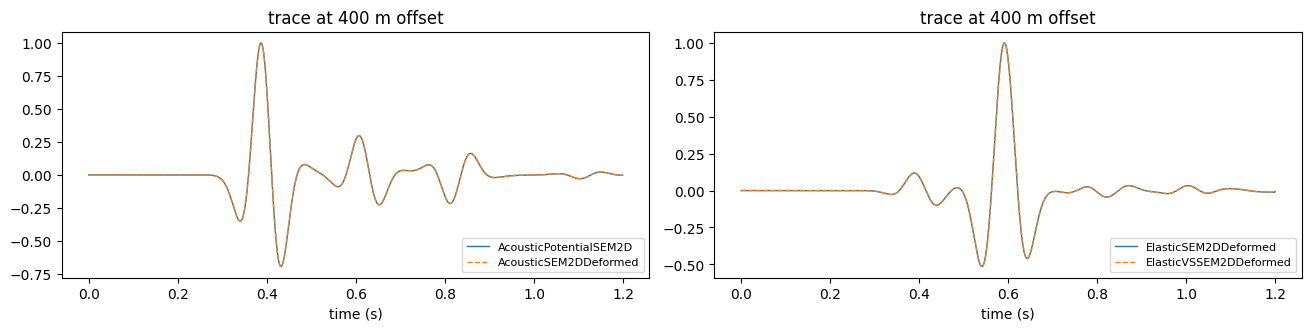

AcousticPotentialSEM2D vs AcousticSEM2DDeformed: relative difference of the normalized gathers 6.6e-06
ElasticSEM2DDeformed vs ElasticVSSEM2DDeformed: relative difference of the normalized gathers 2.2e-02


In [7]:
k = np.argmin(np.abs(rx - (src[0, 0] + 40)))          # 400 m offset
t = np.arange(nt) * dt
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), constrained_layout=True)
for ax, pair in zip(axes, [('AcousticPotentialSEM2D', 'AcousticSEM2DDeformed'),
                           ('ElasticSEM2DDeformed', 'ElasticVSSEM2DDeformed')]):
    for name, ls in zip(pair, ['-', '--']):
        tr = records[name][:, k]
        ax.plot(t, tr / np.abs(tr).max(), ls, lw=1, label=name)
    ax.set_xlabel('time (s)'); ax.legend(loc='lower right', fontsize=8)
    ax.set_title(f'trace at {(rx[k] - src[0, 0]) * dh:.0f} m offset')
plt.show()
for a, b in [('AcousticPotentialSEM2D', 'AcousticSEM2DDeformed'),
             ('ElasticSEM2DDeformed', 'ElasticVSSEM2DDeformed')]:
    ga, gb = records[a], records[b]
    ga, gb = ga / np.abs(ga).max(), gb / np.abs(gb).max()
    print(f'{a} vs {b}: relative difference of the normalized gathers '
          f'{np.linalg.norm(ga - gb) / np.linalg.norm(ga):.1e}')

The acoustic pair agrees as `chi` and `u`. One trap with the derived pressure:
on the potential form `receiver_type=['p']` is `-d²chi/dt²` (SPECFEM's
normalization), while on the pressure form `p` is the field `u` itself. For the
same wavelet the two `p` records therefore differ by two time derivatives:

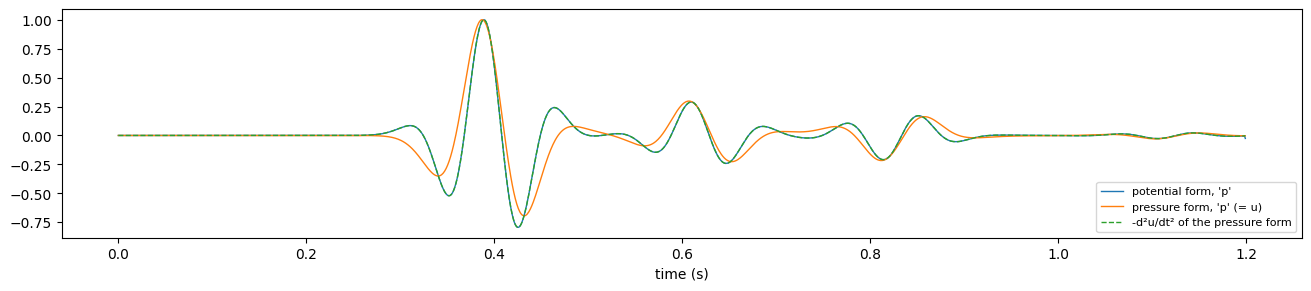

In [8]:
p_pot = PropSEM(AcousticPotentialSEM2D, shape=shape, dh=dh, dt=dt, n_order=n_order,
                abcn=40, free_surface=True, f_dominant=f0, receiver_type=['p'],
                device=device)
with torch.no_grad():
    p = p_pot(wavelet, src, rec, models=[vp])[0, :, k, 0].cpu().numpy()
u = records['AcousticSEM2DDeformed'][:, k]
d2u = -np.gradient(np.gradient(u, dt), dt)
fig, ax = plt.subplots(figsize=(13, 2.8), constrained_layout=True)
ax.plot(t, p / np.abs(p).max(), lw=1, label="potential form, 'p'")
ax.plot(t, u / np.abs(u).max(), lw=1, label="pressure form, 'p' (= u)")
ax.plot(t, d2u / np.abs(d2u).max(), '--', lw=1, label='-d²u/dt² of the pressure form')
ax.set_xlabel('time (s)'); ax.legend(loc='lower right', fontsize=8)
plt.show()

## Summary

- Pick the equation by physics (acoustic, elastic, VTI, fluid–solid, poroelastic)
  and by backend: the `impl='c'` ones are the fast choice for many shots and
  inversion; the rest run eager.
- `solver.model_names` is the `models=` list, in order; models are grid tensors
  of `shape`.
- Changing the equation is a change of the class (and of `models=`); the call
  and the record layout `(nshots, nt, nrec, ncomp)` stay the same.

Next: [SEM basics · 3 — sources, receivers and records](../52_sem_sources_and_receivers/).

---

<p><strong>Download this notebook</strong> &mdash; <a href="51_sem_equations_and_models.ipynb" download><code>51_sem_equations_and_models.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/51_sem_equations_and_models.ipynb">view on GitHub</a></p>